This notebook is written for benchmarking and prototyping the Split-Step Method

Test cases:
1. Dispersion only propagation
2. Soliton in $\chi_{3}$-system
3. Simulton in $\chi_{2}$-system

In [1]:
using BenchmarkTools, TimerOutputs
using CSV, DataFrames, JSON, JLD, OrderedCollections, NPZ
using FFTW, GLM, LinearAlgebra, Random
using LaTeXStrings, ColorSchemes, Plots
using Profile, Base.Threads, ProgressMeter
import Elliptic
import Elliptic.Jacobi
using DifferentialEquations
using Roots

In [358]:
push!(LOAD_PATH, "/home/elaksono/eo-comb/SplitStep/src/");
using Revise
using CUDA
using FileIO
using Constant, Basic
using Materials
using Pulse
using Modulation
using Analytics
using NLOclass, NLO
using SplitStep
using Tests

# Split-step essentials

Split-step method can be used to numerically solve wave propagation through a nonlinear medium. We are interested in solving an equation with the following mathematical form:

$
\begin{equation}
\frac{\partial}{\partial z}\vec{A}(z,T) = (\hat{D}\cdot\vec{A}(z,T) + \hat{N}(\vec{A}(z,T))\cdot\vec{A}(z,T))
\end{equation}
$

The pulse amplitude $A$ is parametrized by $z$, the pulse propagation distance and $T$, the retarded time traveling at the envelope group velocity. The dynamics of the system can also be captured by $\hat{D}$ and $\hat{N}$, which respectively denote the dispersive and nonlinear operators. Split-step simulation essentially exploits the diagonality of the operator $\hat{N}$($\hat{D}$) in the time (frequency) domain, by decomposing the influence of each operator through propagation in time and frequency domain.

Case 1: Nonlinear Schrodinger Equation (NLSE) - $n_{wave} = 1$

$\hat{D}\cdot A(z,T) = -i\frac{\beta_{2}}{2}\frac{\partial^{2}}{\partial T^{2}}A(z,T)$

$\hat{N}(A(z,T))\cdot A(z,T) = i\gamma |A|^{2}A$

Case 2(a): Phase-matched Optical Parametric Amplification - $n_{wave} = 3$

$\vec{A}(z,T) = (A_{s}(z,T)\,\,\,A_{i}(z,T)\,\,\,A_{p}(z,T))^{T}$

$\hat{D}\cdot \vec{A}(z,T) = -\bigg[\frac{\alpha}{2} + \sum^{n}_{k = 1}\beta_{k}\frac{i^{k-1}}{k!}\frac{\partial^{k}}{\partial T^{k}}\bigg]\vec{A}(z,T)$

$
\hat{N}(\vec{A}(z,T))\cdot \vec{A}(z,T) = 
\begin{pmatrix}
\kappa A^{*}_{i}(z,T) A_{p}(z,T)\\
\kappa A^{*}_{s}(z,T) A_{p}(z,T)\\
-\kappa A_{s}(z,T) A_{i}(z,T)\\
\end{pmatrix}
$

Case 2(b): Generalized Optical Parametric Amplification - $n_{wave} = 3$<br>

This allows the treatment of: <br>
(1) Tapering of the coupling coefficient $\kappa \rightarrow \kappa\,g(z)$, <br>
(2) Spatially-varying gratings by encoding it as a phase in the nonlinear process $\phi(z) = \int^{z}_{0}dz'\, [\delta k(\delta\omega)-K_g(z)]$<br>

$\vec{A}(z,T) = (A_{s}(z,T)\,\,\,A_{i}(z,T)\,\,\,A_{p}(z,T))^{T}$

$\hat{D}\cdot \vec{A}(z,T) = -\bigg[\frac{\alpha}{2} + \sum^{n}_{k = 1}\beta_{k}\frac{i^{k-1}}{k!}\frac{\partial^{k}}{\partial T^{k}}\bigg]\vec{A}(z,T)$

$
\hat{N}(\vec{A}(z,T))\cdot \vec{A}(z,T) = 
\begin{pmatrix}
\kappa\,g(z) A^{*}_{i}(z,T) A_{p}(z,T)\,f(\phi(z))\\
\kappa\,g(z) A^{*}_{s}(z,T) A_{p}(z,T)\,f(\phi(z))\\
-\kappa\,g(z) A_{s}(z,T) A_{i}(z,T)\,f^{*}(\phi(z))\\
\end{pmatrix}
$

# Test Materials

In [ ]:
# Comparing different Lithium Niobate Dispersive Relation
lbd_list = collect(0.8:0.1:4.2);
omg_list = (2*pi*c0*1e-6) ./ lbd_list;

n_linbo3e_jundt_list = [n_func(linbo3_e_jundt, omg) for omg in omg_list];
n_linbo3e_gayer_list = [n_func(linbo3_e_gayer, omg) for omg in omg_list];
n_lnlt_list = [n_func(lnlt_z, omg) for omg in omg_list];
n_lnoi_list = [n_func(lnoi_z, omg) for omg in omg_list];

plot()
# plot(lbd_list, n_linbo3e_jundt_list, label = "Zelmon, et al. 1997", frame=:box, xlabel = "λ (μm)", ylabel="n")
# plot!(lbd_list, n_linbo3e_gayer_list, label = "O. Gayer, et al. 2008")
plot!(lbd_list, n_lnlt_list, label = "NTT LNLT")
# plot!(lbd_list, n_lnoi_list, label = "HCP LNOI")

# Simple test cases and benchmarking
This is to simplify the initiation of the process

## Dispersion term convention
Note:
- I checked the correspondence between the analytical expressions for Fourier Components in both time and frequency domain. We see excellent agreement up to a certain propagation length, within which the wave distribution remains within the time window.
- The problem can be overcome by increasing Tmax (the time sampling window)

<b>Split-step and Fourier Transform</b>

The split-step scheme is based on propagation in $z$. We are working in the following frame:

$z' = z, \,\, \tau = t - \beta_{a,1}z$

The electric field amplitude should be given by:

$A(z,t) = a(z,\tau(t,z))e^{i(\omega_{a}t - \beta_{a,0}z)} + c.c.$

Definition for the Fourier transform:

$a(z,\tau) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{\infty} d\omega \,\tilde{a}(z,\omega) e^{i\omega\tau}$ <br>
$\tilde{a}(z,\omega) = \frac{1}{\sqrt{2\pi}}\int_{-\infty}^{\infty} d\tau \,a(z,\tau) e^{-i\omega\tau}$ <br>

The equation of motion (dispersion only) which is consistent with definition above is as follows:

$\partial_{z}a(z,\tau) = -i\beta[-i\partial_{\tau}]a(z,\tau)$

This means the time derivatives lead to the following dispersive terms:

$(-i\partial_{\tau})^{n}a(z,\tau) \rightarrow \omega^{n}\tilde{a}(z,\omega)$

<b>Discrete Fourier Transform vs Continuous Fourier Transform</b>

Julia FFTW definition for the Fourier Transform

$\overline{A}[k] = DFT(A)[k] = \sum_{n=1}^{N}exp[-i\frac{2\pi}{N}(n-1)(k-1)]A[n]$<br>
$A[n] = IDFT(\overline{A})[k] = \frac{1}{N}\sum_{k=1}^{N}exp[i\frac{2\pi}{N}(n-1)(k-1)]\overline{A}[k]$

In the DFT scheme, we need to sample N points within a time window $\Delta T$. It can be shown that the following relationship holds:

$A[n] = A(\frac{n\Delta T}{N})$ <br>
$\overline{A}[k] = \frac{\sqrt{2\pi}N}{\Delta T}.\tilde{A}\bigg(\frac{2\pi(k-1)}{\Delta T}\bigg)$

<b> Units </b>

In my current implementation, we can use the following unit

$\lambda: \mu m$, $t: ps$, $\beta^{(n)}: ps^{n} mm^{-1}$

## Dispersion test

In [439]:
# Central wavelengths
(lbd_p, lbd_s) = (1.064, 1.55);
omg_ctr = freq_lbd_ctr(;lbd_p = lbd_p, lbd_s = lbd_s)["omg"]

# Materials
linbo3_e_taylor = TaylorMaterial("LiNbO3 e-pol", 1.0, omg_ctr, 2, 0.0)
convert_to_TaylorMaterial(linbo3_e_gayer, linbo3_e_taylor, omg_ctr)
linbo3_e_gayer.prop.ll = 10.0
linbo3_e_taylor.prop.ll = 20.0
zero_beta0_t = false

# Pulse properties
pulse1 = pars_pulse()
pulse1.amp_max = [1.0 ; 1.0 ; 1.0];
pulse1.omg_ctr = omg_ctr;
pulse1.T_pulse = [1.0 ; 2.0 ; 0.1];
pulse1.N_div = (2^10);
pulse1.f_pulse = Pulse.ff_gauss; 
pulse_ref_t = 3 # Reference pulse

# The pulsed DOPA properties
disp0 = nl_pulse(linbo3_e_taylor, pulse1; dz = 1e-2, pulse_ref = pulse_ref_t, delta_k=0.0, zero_beta0=zero_beta0_t)
disp1 = nl_pulse(linbo3_e_gayer, pulse1; dz = 1e-2, pulse_ref = pulse_ref_t, delta_k=0.0, zero_beta0=zero_beta0_t);

In [447]:
output0 = opa_dispersion_only(disp0; pulse_amp_vs_t = nothing, pulse_amp_vs_f = pulse_disp_FT, 
    pulse_ref = pulse_ref_t, zero_beta0=zero_beta0_t);
output1 = opa_dispersion_only(disp1; pulse_amp_vs_t = nothing, pulse_amp_vs_f = pulse_disp_FT_fd, 
    pulse_ref = pulse_ref_t, zero_beta0=zero_beta0_t);

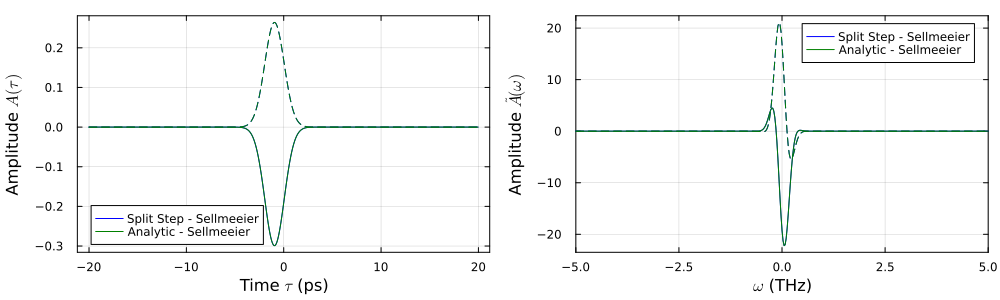

In [504]:
# Propagation in time domain
mat_type_t = "Sellmeeier"
plot_t = plot_opa_dispersion_only(output1, 1; mat_type = mat_type_t)
plot_f = plot_opa_ft_dispersion_only(output1, 1; mat_type = mat_type_t)
plot(plot_t, plot_f, layout = (1,2), size = (1000,300), tight_layout = true, 
    left_margin = 5Plots.mm, bottom_margin = 5Plots.mm, top_margin = 2Plots.mm)

## Simulton in $\chi_{2}$ system
Test case if the dispersion term interacts correctly with the nonlinear term <br>
    We only use the first two entries for DOPA

In [506]:
sml_ωctr = [500.0, 1000.0, 0.0];
sml_taylor = TaylorMaterial("Simulton Taylor Material", 1.0, sml_ωctr, 2, 3.93e-2);

sml_taylor.beta_array = [0.0     0.0    0.0;
                         0.0     0.0    0.0;
                         1.75e-3 3.5e-3 0.0];
sml_taylor.prop.ll = 50.0;

# Simulton pulse properties
pulse_sml1 = pars_pulse()

Amax = 1.2
T_sml1 = sqrt(6 * abs(sml_taylor.beta_array[3,1]) / (sml_taylor.kappa * Amax))

pulse_sml1.amp_max = [Amax ; 0.5 * 1im * Amax ; 0];
pulse_sml1.omg_ctr = sml_ωctr;
pulse_sml1.T_pulse = [T_sml1 ; T_sml1 ; T_sml1];
pulse_sml1.N_div = (2^10);
pulse_sml1.f_pulse = Pulse.ff_sech;

# The pulsed DOPA properties
sml1 = nl_pulse(sml_taylor, pulse_sml1; fac = 10, match_dk = true, delta_k = 0.0);

In [522]:
dopa_sml1 = dopa_simulton(sml1);

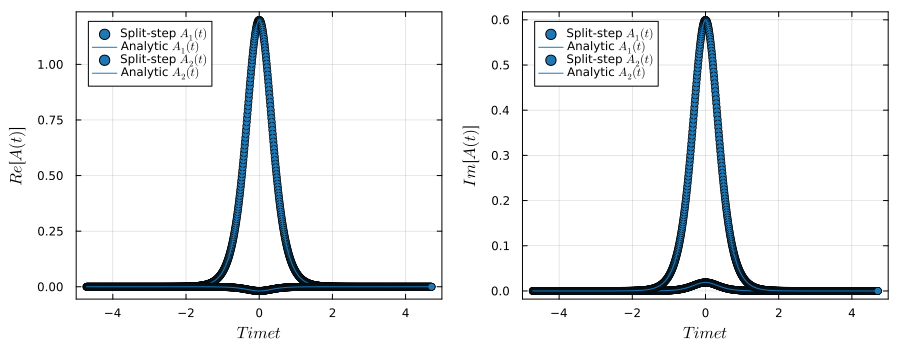

In [531]:
plot_simulton(dopa_sml1, legend=:topleft)

## Adiabatic OPA 

In [4]:
dic_ctr = freq_lbd_ctr(;lbd_p = 1.064, lbd_s = 1.55)
omg_ctr = dic_ctr["omg"]

# Test Materials
# (1) LiNbO3 with second order dispersion
linbo3_e_taylor = TaylorMaterial("LiNbO3 e-pol", 1.0, omg_ctr, 2, 0.0)
convert_to_TaylorMaterial(linbo3_e_gayer, linbo3_e_taylor, omg_ctr)
linbo3_e_taylor.prop.ll = 10.0;
linbo3_e_taylor.kappa = (10.0e-3) / 2;

# (2) LiNbO3 with zero GVD
linbo3_e_gvd0 = deepcopy(linbo3_e_taylor)
linbo3_e_gvd0.prop.name = "LiNbO3 e-pol, no GVD"
linbo3_e_gvd0.beta_array[3,:] = zeros(length(omg_ctr))

# (3) LiNbO3 - phase-matched
linbo3_e_pm = deepcopy(linbo3_e_taylor)
linbo3_e_pm.prop.name = "LiNbO3 e-pol, phase-matched"
linbo3_e_pm.beta_array[1,:] = zeros(length(omg_ctr))

# (4) LiNbO3 - phase-matched, zero GVD
linbo3_e_00 = deepcopy(linbo3_e_gvd0)
linbo3_e_00.prop.name = "LiNbO3 e-pol, phase-matched, zero GVD"
linbo3_e_00.beta_array[1,:] = zeros(length(omg_ctr));

In [8]:
# See the Group Velocity (mm/ps)
gv_s = 1/linbo3_e_taylor.beta_array[2,1];
gv_i = 1/linbo3_e_taylor.beta_array[2,2];
δv_si = 1/(linbo3_e_taylor.beta_array[2,1] - linbo3_e_taylor.beta_array[2,2]);

In [5]:
linbo3_e_taylor = TaylorMaterial("LiNbO3 e-pol", 1.0, omg_ctr, 2, 0.0)
convert_to_TaylorMaterial(linbo3_e_gayer, linbo3_e_taylor, omg_ctr)
linbo3_e_taylor.prop.ll = 10.0;
linbo3_e_taylor.kappa = (10.0e-3) / 2;

In [6]:
# Test for CW
cw1 = pars_pulse()
cw1.amp_max = [100.0 ; 0.0; 1.0e3];
cw1.omg_ctr = dic_ctr["omg"];
cw1.T_pulse = [10.0 ; 10.0 ; 10.0];
cw1.N_div = (2^10);
cw1.f_pulse = Pulse.ff_const;

In [19]:
# The pulsed DOPA properties
FFTW.set_num_threads(1)
const_opa_0 = nl_pulse(linbo3_e_gvd0, cw1; dz = 1e-2, pulse_ref = 1, zero_beta0=true, match_dk = true);
fft_dim = 1;
p_fft1! = plan_fft!(const_opa_0.init_amp, fft_dim);
p_ifft1! = plan_ifft!(const_opa_0.init_amp, fft_dim);

### Special case: CW OPA with a periodically poled LN

In [153]:
# The pulsed DOPA properties
const_opa_0 = nl_pulse(linbo3_e_gvd0, cw1; dz = 1e-2, pulse_ref = 1, zero_beta0=true, match_dk = true);
const_opa_0b  = nl_pulse(linbo3_e_gvd0, cw1; dz = 1e-2, pulse_ref = 1, zero_beta0=true, match_dk = true, 
    delta_k = 0.0);
const_opa_mm = nl_pulse(linbo3_e_gvd0, cw1; dz = 1e-2, pulse_ref = 1, zero_beta0=true, 
    match_dk = false, delta_k = 3e-2);

FFTW.set_num_threads(1)
fft_dim = 1;
p_fft1! = plan_fft!(const_opa_0.init_amp, fft_dim);
p_ifft1! = plan_ifft!(const_opa_0.init_amp, fft_dim);

In [155]:
split_step_nl!(linbo3_e_gvd0.prop.ll, const_opa_0, op_nl_chi2!; record_all = true,
    with_z = false, p_fft = (p_fft1!, p_ifft1!))

In [156]:
split_step_nl!(linbo3_e_gvd0.prop.ll, const_opa_0b, op_nl_adb_chi2!; record_all = true,
    with_z = true, p_fft = (p_fft1!, p_ifft1!))

In [157]:
split_step_nl!(linbo3_e_gvd0.prop.ll, const_opa_mm, op_nl_adb_chi2!; record_all = true,
    with_z = true, p_fft = (p_fft1!, p_ifft1!))

In [113]:
# Light propagation under OPA
# Phaes-matched OPA-CW
arr_zpos = collect(const_opa_0.dz:const_opa_0.dz:linbo3_e_gvd0.prop.ll)

# ODE Solution
test_opa_sol = opa_cw_ode(arr_zpos, 0, const_opa_0);

# Analytic Solution: Jacobi elliptic
test_opa_intensity = [opa_cw_intensity(z, 0.0, const_opa_0) for z in arr_zpos]
test_opa_intensity = hcat(test_opa_intensity...);

# PLOT OPA INTENSITY
opa0_signal = plot(arr_zpos, abs.(const_opa_0.out_amp[1,1,:]).^2, 
    frame=:box, xlabel = "Length z", ylabel = "Φₛ(z)", 
    label="Split-step", legend=:topright, title = "Phase-matched OPA (Δk = 0)")

plot!(opa0_signal, arr_zpos, abs.(test_opa_sol["flux"][1,:]), color=:red, linestyle=:dash, label = "ODE Solver")
plot!(opa0_signal, arr_zpos, abs.(test_opa_intensity[1,:]), color=:blue, linestyle=:dash, label = "Analytical")

opa0_idler = plot(arr_zpos, abs.(const_opa_0.out_amp[1,2,:]).^2, label="Split-step",
    xlabel = "Length z", ylabel = "Φᵢ(z)", frame=:box, legend=:topright)
plot!(opa0_idler, arr_zpos, abs.(test_opa_sol["flux"][2,:]), color=:red, linestyle=:dash, label = "ODE Solver")
plot!(opa0_idler, arr_zpos, abs.(test_opa_intensity[2,:]), color=:blue, linestyle=:dash, label = "Analytical")

opa0_pump = plot(arr_zpos, abs.(const_opa_0.out_amp[1,3,:]).^2, label="Split-step",
    xlabel = "Length z", ylabel = "Φₚ(z)", frame=:box, legend=:topright)
plot!(opa0_pump, arr_zpos, abs.(test_opa_sol["flux"][3,:]), color=:red, linestyle=:dash, label = "ODE Solver")
plot!(opa0_pump, arr_zpos, abs.(test_opa_intensity[3,:]), color=:blue, linestyle=:dash, label = "Analytical")

opa0_plot = plot(opa0_signal, opa0_idler, opa0_pump, layout = (3,1), size = (800,800))

# savefig("figures/test_OPA_dk0.png")
opa0_plot

In [114]:
# Test the function
# The pulsed DOPA properties
const_opa_0 = nl_pulse(linbo3_e_gvd0, cw1; dz = 1e-2, pulse_ref = 1, zero_beta0=true, match_dk = true);

linbo3_e_gvd0.prop.ll = 10.0
arr_zpos = collect(const_opa_0.dz:const_opa_0.dz:linbo3_e_gvd0.prop.ll)

split_step_nl!(linbo3_e_gvd0.prop.ll, const_opa_0, op_nl_chi2!; record_all = true, step_method = rk4_step_nl!,
    with_z = false, p_fft = (p_fft1!, p_ifft1!))

In [115]:
# ODE Solution
test_opa_sol = opa_cw_ode(arr_zpos, 0, const_opa_0);
# Analytic Solution
test_opa_intensity = [opa_cw_intensity(z, 0.0, const_opa_0) for z in arr_zpos]
test_opa_intensity = hcat(test_opa_intensity...);

GKS: Possible loss of precision in routine SET_WINDOW


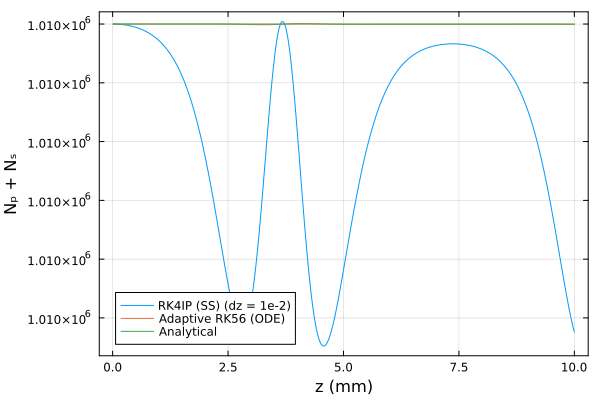

In [116]:
mrowe_plot = plot(xlabel = "z (mm)", ylabel = "Nₚ + Nₛ", frame=:box)
plot!(mrowe_plot, arr_zpos, abs.(const_opa_0.out_amp[1,1,:]).^2 .+ abs.(const_opa_0.out_amp[1,3,:]).^2, 
    label = "RK4IP (SS) (dz = 1e-2)")
plot!(mrowe_plot, arr_zpos, test_opa_sol["flux"][1,:] .+ test_opa_sol["flux"][3,:], label = "Adaptive RK56 (ODE)")
plot!(mrowe_plot, arr_zpos, test_opa_intensity[1,:] .+ test_opa_intensity[3,:], label = "Analytical")
savefig("./figures/manley_rowe_opa_cw.png")

mrowe_plot

In [117]:
# Phaes-mismatched OPA-CW
arr_zpos = collect(const_opa_mm.dz:const_opa_mm.dz:linbo3_e_gvd0.prop.ll)

# ODE Solution
opa_mm_sol = opa_cw_ode(arr_zpos, const_opa_mm.delta_k, const_opa_mm);
# Analytic Solution
opa_mm_intensity = [opa_cw_intensity(z, const_opa_mm.delta_k, const_opa_mm) for z in arr_zpos]
opa_mm_intensity = hcat(opa_mm_intensity...);

opa_mm_signal = plot(arr_zpos, abs.(const_opa_mm.out_amp[1,1,:]).^2, 
    frame=:box, xlabel = "Length z", ylabel = "Φₛ(z)", 
    label="Split-step", legend=:topright,
    title = "Phase-mismatched OPA (Δk = " * string(round(const_opa_mm.delta_k, digits=3)) * " μm)"

)

# PLOT OPA INTENSITY
plot!(opa_mm_signal, arr_zpos, abs.(opa_mm_sol["flux"][1,:]), color=:red, linestyle=:dash, label = "ODE Solver")
plot!(opa_mm_signal, arr_zpos, abs.(opa_mm_intensity[1,:]), color=:blue, linestyle=:dash, label = "Analytical")

opa_mm_idler = plot(arr_zpos, abs.(const_opa_mm.out_amp[1,2,:]).^2, label="Split-step",
    xlabel = "Length z", ylabel = "Φᵢ(z)", frame=:box, legend=:topright)
plot!(opa_mm_idler, arr_zpos, abs.(opa_mm_sol["flux"][2,:]), color=:red, linestyle=:dash, label = "ODE Solver")
plot!(opa_mm_idler, arr_zpos, abs.(opa_mm_intensity[2,:]), color=:blue, linestyle=:dash, label = "Analytical")

opa_mm_pump = plot(arr_zpos, abs.(const_opa_mm.out_amp[1,3,:]).^2, label="Split-step",
    xlabel = "Length z", ylabel = "Φₚ(z)", frame=:box, legend=:topright)
plot!(opa_mm_pump, arr_zpos, abs.(opa_mm_sol["flux"][3,:]), color=:red, linestyle=:dash, label = "ODE Solver")
plot!(opa_mm_pump, arr_zpos, abs.(opa_mm_intensity[3,:]), color=:blue, linestyle=:dash, label = "Analytical")

opa_mm_plot = plot(opa_mm_signal, opa_mm_idler, opa_mm_pump, layout = (3,1), size = (800,800))
# savefig("figures/test_OPA_dk" * string(round(const_opa_mm.delta_k, digits=3)) * ".png")
opa_mm_plot

LoadError: UndefVarError: `const_opa_mm` not defined

### CW OPA with a linearly chirped LN

In [118]:
# Test for CW
lbd_p = 1.064; lbd_s = 1.55;

cw2 = pars_pulse()
cw2.amp_max = [100.0 ; 0.0; 1.0e3];

cw2.omg_ctr = freq_lbd_ctr(lbd_p = lbd_p, lbd_s = lbd_s)["omg"]
cw2.T_pulse = [10.0 ; 10.0 ; 10.0];
cw2.N_div = (2^10);
cw2.f_pulse = Pulse.ff_const;

delta_beta_0 = (beta_func(linbo3_e_gayer, cw2.omg_ctr[3]) - beta_func(linbo3_e_gayer, cw2.omg_ctr[1]) - 
    beta_func(linbo3_e_gayer, cw2.omg_ctr[2]));
qpm_lambda_0 = 1e3 * 2*pi/ delta_beta_0;

In [119]:
# Linearly chirped OPA
linbo3_e_gayer.prop.ll = 10.0
linbo3_e_gayer.kappa = 1.0e-3
(zc_t, alpha_t) = (linbo3_e_gayer.prop.ll/2, 1.0)

lin_opa = nl_pulse_adb(linbo3_e_gayer, cw2; dz = 1e-2, pulse_ref = 1, zero_beta0=true, 
    match_dk = true, qpm_lambda = qpm_lambda_0, 
    phi_z_func = phi_z_lin, phi_z_pars = (zc_t, alpha_t));
arr_zpos = collect(lin_opa.dz:lin_opa.dz:linbo3_e_gayer.prop.ll)

arr_ωs_z = [solve_ωs_for_z(z, cw2.omg_ctr, qpm_lambda_0, linbo3_e_gayer, (zc_t, alpha_t)) for z in arr_zpos];
arr_λs_z = (2*pi*c0*1e-12) ./ (arr_ωs_z) * 1e6;

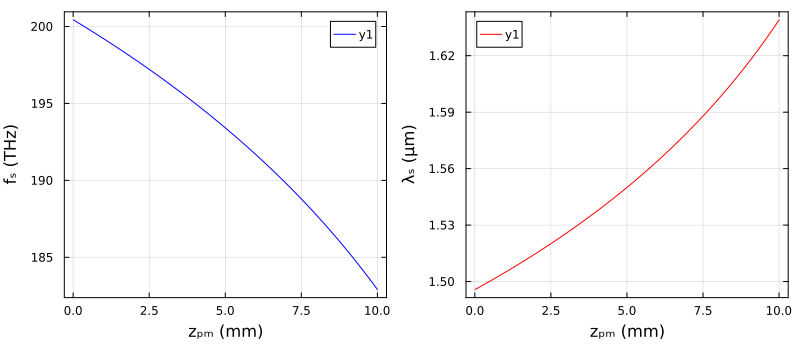

In [120]:
pm_plot_1 = plot(arr_zpos, arr_ωs_z ./ (2*pi), frame=:box, xlabel = "zₚₘ (mm)", ylabel = "fₛ (THz)", color=:blue, 
    leftmargin=3Plots.mm, bottommargin=5Plots.mm)
pm_plot_2 = plot(arr_zpos, arr_λs_z, frame=:box, xlabel = "zₚₘ (mm)", ylabel = "λₛ (μm)", color=:red, leftmargin=3Plots.mm)
plot(pm_plot_1, pm_plot_2, size = (800,350))

#### OPA Intensity vs propagation distance

In [121]:
split_step_nl!(linbo3_e_gayer.prop.ll, lin_opa, op_nl_adb_chi2!; record_all = true,
    with_z = true, p_fft = (p_fft1!, p_ifft1!))

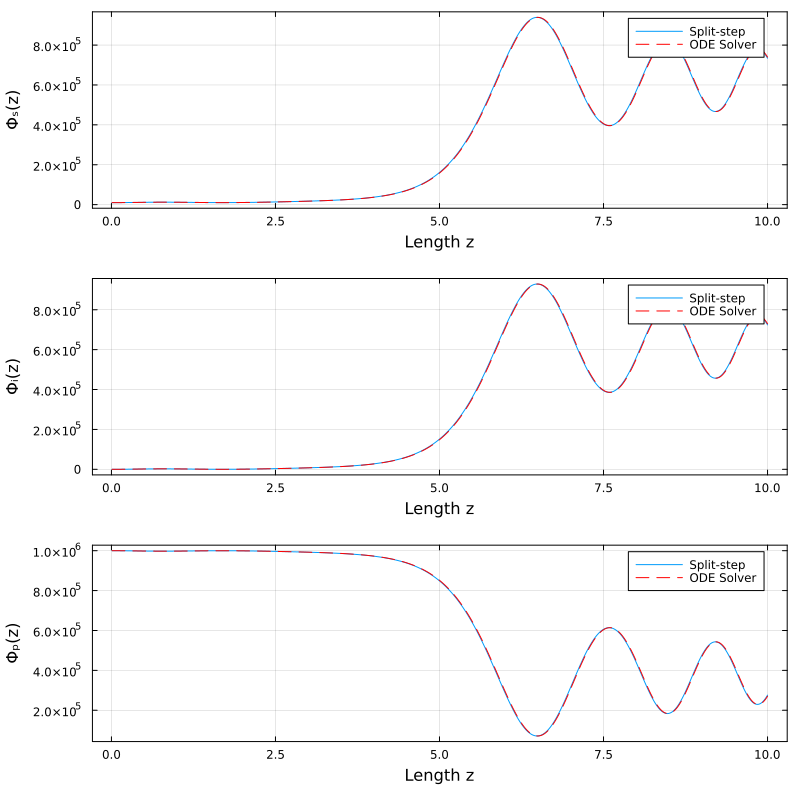

In [122]:
# Phaes-mismatched OPA-CW
# ODE Solution
lin_opa_sol = opa_cw_ode(arr_zpos, lin_opa.delta_k, lin_opa);

# PLOT OPA INTENSITY
lin_opa_signal = plot(arr_zpos, abs.(lin_opa.out_amp[1,1,:]).^2, 
    frame=:box, xlabel = "Length z", ylabel = "Φₛ(z)", 
    label="Split-step", legend=:topright)
plot!(lin_opa_signal, arr_zpos, abs.(lin_opa_sol["flux"][1,:]), color=:red, linestyle=:dash, label = "ODE Solver")

lin_opa_idler = plot(arr_zpos, abs.(lin_opa.out_amp[1,2,:]).^2, label="Split-step",
    xlabel = "Length z", ylabel = "Φᵢ(z)", frame=:box, legend=:topright)
plot!(lin_opa_idler, arr_zpos, abs.(lin_opa_sol["flux"][2,:]), color=:red, linestyle=:dash, label = "ODE Solver")

lin_opa_pump = plot(arr_zpos, abs.(lin_opa.out_amp[1,3,:]).^2, label="Split-step",
    xlabel = "Length z", ylabel = "Φₚ(z)", frame=:box, legend=:topright)
plot!(lin_opa_pump, arr_zpos, abs.(lin_opa_sol["flux"][3,:]), color=:red, linestyle=:dash, label = "ODE Solver")

lin_opa_plot = plot(lin_opa_signal, lin_opa_idler, lin_opa_pump, layout = (3,1), size = (800,800))
# savefig("figures/test_lin_OPA.png")
lin_opa_plot

#### Calculating the gain bandwidth

In [207]:
mat1 = linbo3_e_gvd0
mat2 = linbo3_e_gayer

mat1.prop.ll = 20.0
mat1.kappa = 1.0e-3
(zc_t, dk1_t) = (mat1.prop.ll/2, 1.0)
qpm_e1 = 2*pi*1e3/(beta_func(mat1,omg_ctr[3],3) - beta_func(mat1,omg_ctr[1],1) - 
    beta_func(mat1,omg_ctr[2],2))

cw2 = pars_pulse()
cw2.amp_max = [0.1 ; 0.0; sqrt(2) * 1.0e3];
cw2.T_pulse = [10.0 ; 10.0 ; 10.0];
cw2.N_div = (2^5);
cw2.f_pulse = Pulse.ff_const;

lbd_s_vec = collect(1.4:0.001:1.7);
out_s_vec = zeros(ComplexF64,length(lbd_s_vec));
out_i_vec = zeros(ComplexF64,length(lbd_s_vec));
gain_vec = zeros(length(lbd_s_vec));
gain_rsb_vec = zeros(length(lbd_s_vec));
phase_s_vec = zeros(length(lbd_s_vec));
phase_i_vec = zeros(length(lbd_s_vec));
phase_s_rsb_vec = zeros(length(lbd_s_vec));
phase_i_rsb_vec = zeros(length(lbd_s_vec));

dbeta_si = mat1.beta_array[2,1] - mat1.beta_array[2,2];
freq_s_vec = c0*1e-12 ./ (lbd_s_vec * 1e-6);
omega_s_vec = (2*pi) .* freq_s_vec;
domega_s_vec = omega_s_vec .- mat1.omega_c[1];
norm_domega_s_vec = (dbeta_si/sqrt(dk1_t)) .* domega_s_vec;
kL_const = sqrt(dk1_t) * mat1.prop.ll;

for (i, lbd_s) in enumerate(lbd_s_vec)
    cw2.omg_ctr = freq_lbd_ctr(lbd_p = lbd_p, lbd_s = lbd_s)["omg"]
    lin_opa1 = nl_pulse_adb(mat1, cw2; dz = 5e-2, pulse_ref = 1, zero_beta0=true, 
        match_dk = false, qpm_lambda= qpm_e1, phi_z_func = phi_z_lin, phi_z_pars = (zc_t, dk1_t));
    p_fft! = plan_fft!(lin_opa1.init_amp, fft_dim);
    p_ifft! = plan_ifft!(lin_opa1.init_amp, fft_dim);
    
    split_step_nl!(mat1.prop.ll, lin_opa1, op_nl_adb_chi2!; record_all = false,
        with_z = true, p_fft = (p_fft!, p_ifft!), step_method = rk4_step_nl!)
    
    out_s_vec[i] = lin_opa1.out_amp[1,1]
    phase_s_vec[i] = angle(out_s_vec[i])
    out_i_vec[i] = lin_opa1.out_amp[1,2]
    phase_i_vec[i] = angle(out_i_vec[i])
    gain_vec[i] = abs(out_s_vec[i]/ lin_opa1.init_amp[1,1])
    
    # Rosenbluth approximation
    gain_rsb_vec[i] = gain_rsb_lbd(lbd_s, lin_opa1)
    phase_i_rsb_vec[i] = phase_rsb_lbd(lbd_s, lin_opa1)
end

In [162]:
phase_rsb_lbd(lbd_s, lin_opa1)

1.8362787842313755

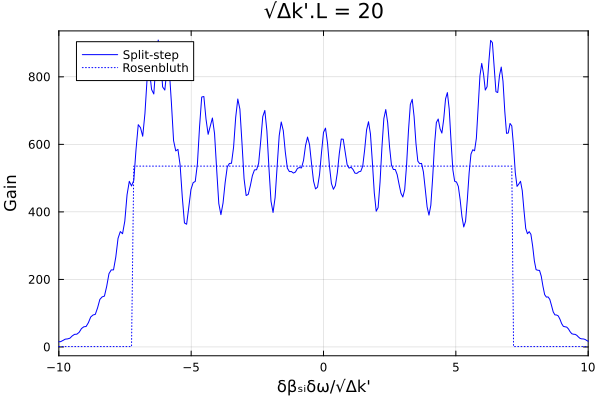

In [211]:
plot(xlim=(-10,10), frame=:box, title = "√Δk'.L = 20", xlabel = "δβₛᵢδω/√Δk'", ylabel = "Gain")
plot!(norm_domega_s_vec, gain_vec, color=:blue, label = "Split-step")
plot!(norm_domega_s_vec, gain_rsb_vec, color=:blue, linestyle=:dot, label = "Rosenbluth")

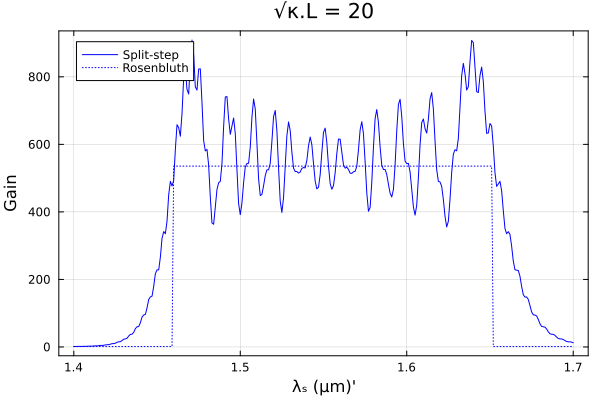

In [190]:
plot(frame=:box, title = "√Δk'.L = 20", xlabel = "λₛ (μm)'", ylabel = "Gain")
plot!(lbd_s_vec, gain_vec, color=:blue, label = "Split-step")
plot!(lbd_s_vec, gain_rsb_vec, color=:blue, linestyle=:dot, label = "Rosenbluth")

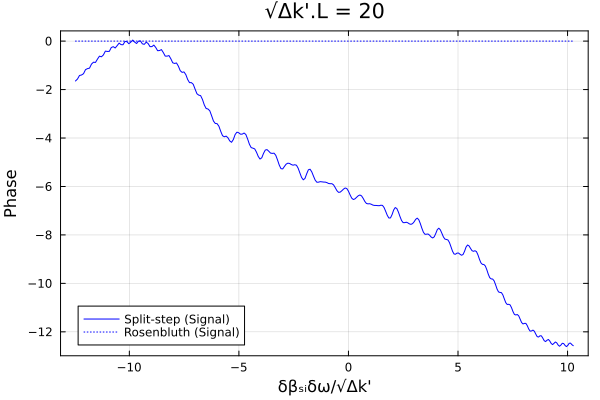

In [205]:
plot(frame=:box, title = "√Δk'.L = 20", xlabel = "δβₛᵢδω/√Δk'", ylabel = "Phase")
plot!(norm_domega_s_vec, angle_s_vec, color=:blue, label = "Split-step (Signal)")
plot!(norm_domega_s_vec, angle_s_rsb_vec, color=:blue, linestyle=:dot, label = "Rosenbluth (Signal)")

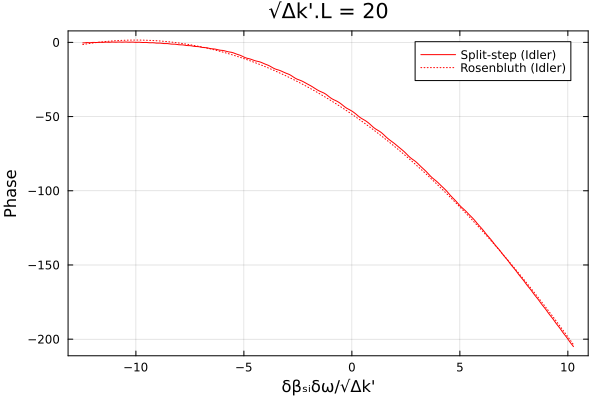

In [204]:
plot(frame=:box, title = "√Δk'.L = 20", xlabel = "δβₛᵢδω/√Δk'", ylabel = "Phase")
plot!(norm_domega_s_vec, angle_i_vec, color=:red, label = "Split-step (Idler)")
plot!(norm_domega_s_vec, angle_i_rsb_vec, color=:red, linestyle=:dot, label = "Rosenbluth (Idler)")

### Threshold power vs bandwidth

In [227]:
κ_test = 5.0e-3 * sqrt(1e-3) / (10) # mm^-1 ps^1/2
L_wg = 30.0 # mm
loss = 0.75 # 6dB

dk_1_vec = range(0.0, stop=0.25, length=100)
wg_mat_test = lnlt_z;

# Test for CW
(λp, λs) = [1.064e-6, 1.55e-6];
omg_ctr_test = (2*pi*3e8*1e-12) ./ [λs; (λs * λp)/(λs - λp); λp;];
(Ep, Es, Ei) = (hbar*1e12) .* omg_ctr_test

delta_beta_test = (beta_func(wg_mat_test, omg_ctr_test[3]) - beta_func(wg_mat_test, omg_ctr_test[1]) - 
    beta_func(wg_mat_test, omg_ctr_test[2]))
qpm_lambda_test = 1e3 * 2*pi/ delta_beta_test

# Linearly chirped OPA
lnlt_z.prop.ll = L_wg
lnlt_z.kappa = κ_test
(zc_t, dk_1_t) = (lnlt_z.prop.ll/2, 1.0);

In [22]:
solve_bw_lbd_linear(omg_ctr_test, qpm_lambda_test, lnlt_z, (zc_t, 2.5e-1))

LoadError: UndefVarError: `omg_ctr_test` not defined

In [23]:
solve_bw_lbd_con(omg_ctr_test, qpm_lambda_test, lnlt_z)["bw_lbd"]

LoadError: UndefVarError: `omg_ctr_test` not defined

In [181]:
dk_1_vec

0.0:0.0025252525252525255:0.25

In [228]:
cth_1 = [cth_cw_opo(loss, κ_test, L_wg) for i in 1:length(dk_1_vec)];
cth_2 = [cth_cw_opo_lin(loss, κ_test, dk) for dk in dk_1_vec];

Pth_1 = abs2.(cth_1) .* (Ep * 1e12);
Pth_2 = abs2.(cth_2) .* (Ep * 1e12);

bw_con = [solve_bw_con(omg_ctr_test, qpm_lambda_test, lnlt_z) for dk in dk_1_vec];
bw_lbd_con = [solve_bw_lbd_con(omg_ctr_test, qpm_lambda_test, lnlt_z)["bw_lbd"] for dk in dk_1_vec];
bw_adb = [solve_bw_linear(omg_ctr_test, qpm_lambda_test, lnlt_z, (zc_t, dk)) for dk in dk_1_vec];
bw_lbd_adb = [solve_bw_lbd_linear(omg_ctr_test, qpm_lambda_test, lnlt_z, (zc_t, dk))["bw_lbd"] for dk in dk_1_vec];

In [199]:
collect(dk_1_vec)

100-element Vector{Float64}:
 0.0
 0.0025252525252525255
 0.005050505050505051
 0.007575757575757576
 0.010101010101010102
 0.012626262626262626
 0.015151515151515152
 0.017676767676767676
 0.020202020202020204
 0.022727272727272728
 0.025252525252525252
 0.027777777777777776
 0.030303030303030304
 ⋮
 0.2222222222222222
 0.22474747474747475
 0.22727272727272727
 0.2297979797979798
 0.23232323232323232
 0.23484848484848486
 0.23737373737373738
 0.2398989898989899
 0.24242424242424243
 0.24494949494949494
 0.2474747474747475
 0.25

In [229]:
δkL(δω) = (beta_func(wg_mat_test, omg_ctr_test[3]) - beta_func(wg_mat_test, omg_ctr_test[1] + δω) - 
    beta_func(wg_mat_test, omg_ctr_test[2] - δω) - 2*pi/(qpm_lambda_test*1e-3) ) * wg_mat_test.prop.ll;

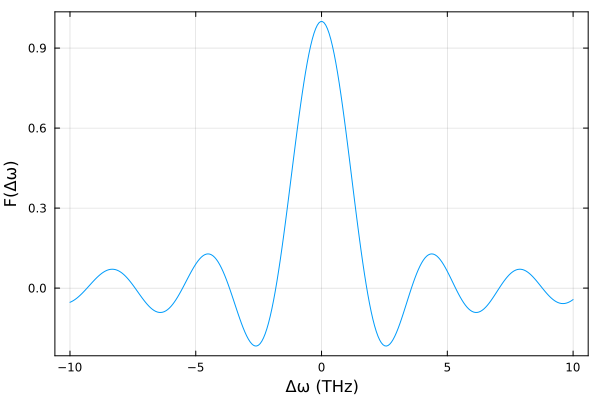

In [230]:
dω_vec = range(-10.0, stop = 10.0, length = 300)
sinc_vec = [sin(0.5*δkL(dω))/(0.5*δkL(dω)) for dω in dω_vec]
plot(dω_vec, sinc_vec, frame=:box, xlabel = "Δω (THz)", ylabel = "F(Δω)", label=nothing)

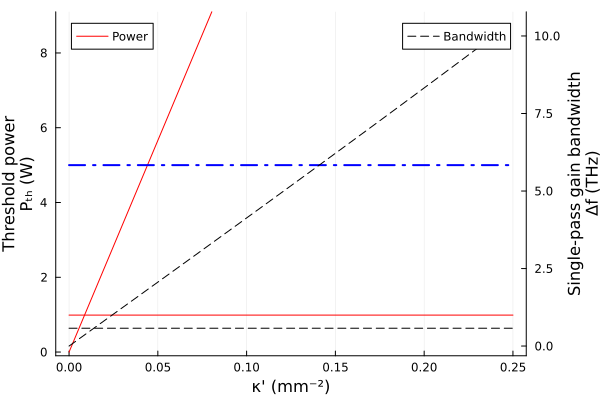

In [231]:
axis2 = plot(frame=:box, xlabel = "κ' (mm⁻²)", legends=:topleft, ylim = (-0.1, 9.1))
plot!(axis2, dk_1_vec, Pth_1, label="Power", ylabel = "Threshold power\nPₜₕ (W)", color=:red)
plot!(axis2, dk_1_vec, Pth_2, label=nothing, color=:red)
plot!(axis2, dk_1_vec, 5. .* ones(length(dk_1_vec)), color=:blue, linestyle=:dashdot, linewidth=2.0, label=nothing)

axis2 = twinx()
plot!(axis2, dk_1_vec, bw_con ./ (2*pi), label="Bandwidth", ylabel = "Single-pass gain bandwidth\nΔf (THz)", 
    color=:black, linestyle=:dash, legends=:topright)
plot!(axis2, dk_1_vec, bw_adb ./ (2*pi), label=nothing, color=:black, linestyle=:dash)

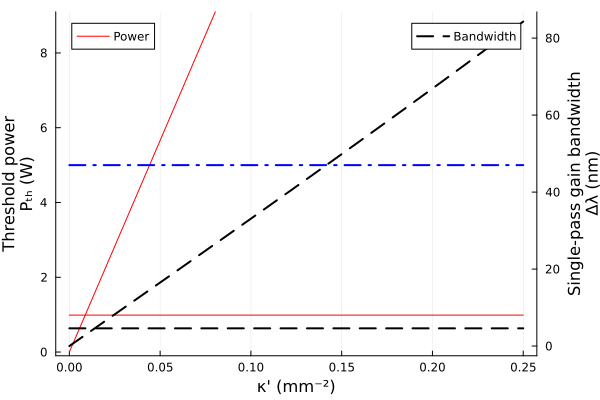

In [232]:
axis1 = plot(frame=:box, xlabel = "κ' (mm⁻²)", legends=:topleft, ylim = (-0.1, 9.1))
plot!(axis1, dk_1_vec, Pth_1, label="Power", ylabel = "Threshold power\nPₜₕ (W)", color=:red)
plot!(axis1, dk_1_vec, Pth_2, label=nothing, color=:red)
plot!(axis1, dk_1_vec, 5.0 .* ones(length(dk_1_vec)), color=:blue, linestyle=:dashdot, linewidth=2.0, label=nothing)

axis1 = twinx()
plot!(axis1, dk_1_vec, bw_lbd_con .* 1e3, label="Bandwidth", ylabel = "Single-pass gain bandwidth\nΔλ (nm)", 
    color=:black, linestyle=:dash, legends=:topright, linewidth = 2.0)
plot!(axis1, dk_1_vec, bw_lbd_adb .* 1e3, label=nothing, color=:black, linestyle=:dash, linewidth = 2.0)

savefig("./figures/Pth_BW_linear_chirp.png")

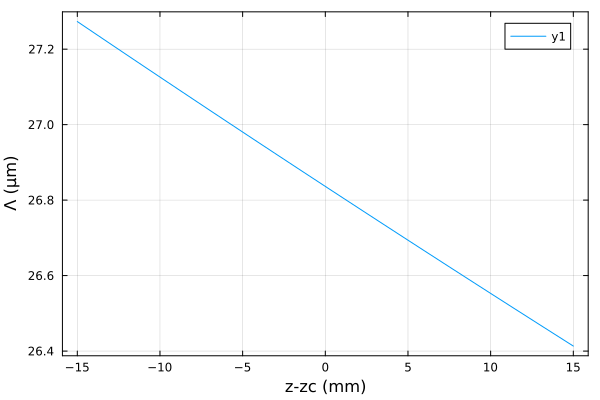

In [72]:
dk_1_val = 0.25
z_vec = range(0.0, stop = wg_mat_test.prop.ll, length = 100) .- wg_mat_test.prop.ll/2
delta_beta_vec = [delta_beta_test .+ dk_1_val .* z for z in z_vec]
lbd_qpm_vec = (2*pi*1e3) ./ delta_beta_vec

plot(z_vec, lbd_qpm_vec, frame=:box, xlabel = "z-zc (mm)", ylabel = "Λ (μm)")

## Benchmarking the split step method

In [130]:
# Simulton: k2"/k1" = 2
dopa1 = pars_nl()
dopa1.βnl = .- [0.0      0.0   ;
                0.0      0.0   ;
                1.75e-3  3.5e-3];
dopa1.ωnl = [0.2 ; 0.4];
dopa1.κnl = 3.93e-2;

# Pulse properties
pulse_sml1 = pars_pulse()

# Specific for simulton
Amax = 1.2
T_sml1 = sqrt(6 * abs(dopa1.βnl[3,1]) / (dopa1.κnl * Amax))

pulse_sml1.amp_max = [Amax ; 0.5 * 1im * Amax];
pulse_sml1.T_pulse = [T_sml1 ; T_sml1];
pulse_sml1.N_div = (2^10);
pulse_sml1.f_pulse = Pulse.ff_sech;

# The pulsed DOPA properties
sml1 = nl_pulse(dopa1, pulse_sml1; fac = 10);

FFTW.set_num_threads(1)
p_fft1! = plan_fft!(sml1.init_amp, 1);
p_ifft1! = plan_ifft!(sml1.init_amp, 1);

Benchmarking the duration & allocation, just for a single core

In [136]:
dz = 0.1
@btime split_step_nl!(dz, sml1, op_nl_dopa!, step_method = naive_step_nl!, p_fft = (p_fft1!, p_ifft1!))
@btime split_step_nl!(dz, sml1, op_nl_dopa!, step_method = rk4_step_nl!, p_fft = (p_fft1!, p_ifft1!))

  86.792 μs (65 allocations: 34.67 KiB)
  397.251 μs (308 allocations: 126.34 KiB)


In [137]:
Lz = 10
@btime split_step_nl!(Lz, sml1, op_nl_dopa!, step_method = naive_step_nl!, p_fft = (p_fft1!, p_ifft1!))
@btime split_step_nl!(Lz, sml1, op_nl_dopa!, step_method = rk4_step_nl!, p_fft = (p_fft1!, p_ifft1!))

  7.515 ms (5214 allocations: 245.89 KiB)
  41.817 ms (29513 allocations: 9.19 MiB)


In [134]:
@profile split_step_nl!(Lz, sml1, op_nl_dopa!, step_method = rk4_step_nl!)

In [135]:
Profile.print(format=:flat)

 Count  Overhead File                    Line Function
 =====  ======== ====                    ==== ========
     1         0 @Base/abstractarray.jl  1245 _getindex
     1         0 @Base/abstractarray.jl  2572 _sub2ind
     1         0 @Base/abstractarray.jl  2588 _sub2ind
     1         0 @Base/abstractarray.jl  2604 _sub2ind_recurse
     1         0 @Base/abstractarray.jl  1251 _to_linear_index
     1         0 @Base/abstractarray.jl  1218 getindex
     1         0 @Base/array.jl           353 fill!
     1         1 @Base/array.jl           903 setindex!
     1         0 @Base/array.jl           520 zeros(::Int64, ::Int64)
     1         0 @Base/array.jl           522 zeros
     1         0 @Base/array.jl           526 zeros
    24         2 @Base/boot.jl            373 eval
     1         0 @Base/broadcast.jl       636 _broadcast_getindex
     4         0 @Base/broadcast.jl       642 _broadcast_getindex
     4         0 @Base/broadcast.jl       643 _broadcast_getindex
     4      

### Tracking allocations line-by-line
Building block: naive_step

In [110]:
function naive_step_test!(dz, dpulse, op_nl; 
                        is_linear = false, p_fft = nothing, cache_id = 1, fft_dim = 1)
    @time temp = @view dpulse.temp_amp[:,:,cache_id]
    @time is_linear ? temp .= zeros(size(temp)...) : op_nl(dz, dpulse; cache_id = cache_id)
    @time dpulse.current_amp .= temp .+ dpulse.current_amp
    @time fw_disp!(dz, dpulse, p_fft = p_fft, fft_dim = fft_dim)
    return
end;

In [71]:
@time op_nl_dopa!(0.1, sml1; cache_id = 2)

  0.000120 seconds (32 allocations: 1.391 KiB)


In [115]:
naive_step_test!(0.2, sml1, op_nl_dopa!, is_linear = false, p_fft = (p_fft1!, p_ifft1!))

  0.000010 seconds (4 allocations: 144 bytes)
  0.000130 seconds (30 allocations: 1.375 KiB)
  0.000041 seconds (2 allocations: 128 bytes)
  0.000284 seconds (14 allocations: 448 bytes)


## Parallel code for split step

### Constructing a vector of objects

In [63]:
# Test case: Different simulton parametrizations
# Simulton: k2"/k1" = 2
dopa1 = pars_nl()
dopa1.βnl = .- [0.0      0.0;      
                0.0      0.0;
                1.75e-3  3.5e-3];
dopa1.ωnl = [0.2 ; 0.4];
dopa1.κnl = 3.93e-2;

In [64]:
len_pulse = 80;
id_thread = zeros(len_pulse)
sml_vec = Array{nl_pulse}(undef, len_pulse)

Abound = 6.0
dAmax = (Abound/len_pulse)
Amax_vec = collect(dAmax:dAmax:Abound)

# === Instantiate multiple objects ===
# In this case, we are just varying the pump/ signal amplitudes
for (i,Amax) in enumerate(Amax_vec)
    pulse_sml = pars_pulse()
    
    # Simulton width
    T_sml = sqrt(6 * abs(dopa1.βnl[3,1]) / (dopa1.κnl * Amax))

    pulse_sml.amp_max = [Amax ; 0.5 * 1im * Amax];
    pulse_sml.T_pulse = [T_sml; T_sml];
    pulse_sml.N_div = (2^10);
    pulse_sml.f_pulse = Pulse.ff_sech;

    sml_vec[i] = nl_pulse(dopa1, pulse_sml; fac = 10);
end

p_fft1! = plan_fft!(sml_vec[1].init_amp, 1);
p_ifft1! = plan_ifft!(sml_vec[1].init_amp, 1);

### Benchmarking FFTW behaviours

Benchmarking FFT behaviours for different nthreads <br>
<b> Resolved </b>: The gain is observed in the larger cases. Multithreading is implemented internally using FFTW library in C

In [ ]:
# It can be faster to simply use single threading for FFTW
Nthmax = 10;
t0vec = zeros(Nthmax)
tpvec = zeros(Nthmax)
for i in collect(1:Nthmax)
    FFTW.set_num_threads(i)
    # FFT
    t0vec[i] = @belapsed fft(sml1.init_amp[1,:])
    
    # Planned FFT
    p_fft1 = plan_fft(sml_vec[1].init_amp[1,:]);
    tpvec[i] = @belapsed p_fft1 * sml1.init_amp[1,:]
end

In [ ]:
plot(t0vec, xlabel = "Number of threads", ylabel = "Time (s)", frame=:box, label="FFTW")
plot!(tpvec, label = "Planned FFTW")

### Calculating multiple cases with multithreading

Check if we can have any gain from using multiple threads <br>
- Seems like we can get ~10x speed up with 40 threads

In [140]:
# Split-step: one instance only, 10 steps
Lz = 1.0;
FFTW.set_num_threads(1);
@btime split_step_nl!(0.1, sml_vec[3], op_nl_dopa!, dz=0.1, step_method = naive_step_nl!, p_fft = (p_fft1, p_ifft1))

  78.334 μs (65 allocations: 34.70 KiB)


In [141]:
@btime split_step_nl!(0.1, sml_vec[3], op_nl_dopa!, dz=0.1, step_method = rk4_step_nl!, p_fft = (p_fft1, p_ifft1))

  384.167 μs (311 allocations: 126.44 KiB)


In [142]:
@btime split_step_nl!(Lz, sml_vec[3], op_nl_dopa!, step_method = rk4_step_nl!, p_fft = (p_fft1, p_ifft1))

  3.866 ms (2963 allocations: 970.59 KiB)


In [143]:
# Using multi-threading
@btime Threads.@threads for i in collect(1:length(sml_vec))
    id_thread[i] = Threads.threadid()
    split_step_nl!(Lz, sml_vec[i], op_nl_dopa!, step_method = rk4_step_nl!, p_fft = (p_fft1, p_ifft1))
end

  20.326 ms (237243 allocations: 75.85 MiB)


In [144]:
# Simply for loops
@btime for i in collect(1:length(sml_vec))
    id_thread[i] = Threads.threadid()
    split_step_nl!(Lz, sml_vec[i], op_nl_dopa!, step_method = rk4_step_nl!, p_fft = (p_fft1, p_ifft1))
end

  350.420 ms (237122 allocations: 75.83 MiB)


In [146]:
sml_vec[1].arr_time

0.03686360311437002

### Trying CUDA
I definitely see a speed up using CUDA

In [72]:
# sml_vec is the list of dopa parameters
sml_cuda = nl_pulse_p(sml_vec);

In [74]:
size(sml_cuda.init_amp_p)

(1024, 80, 2)

In [8]:
L = 0.1
p_fft_cuda! = plan_fft!(sml_cuda.current_amp_p, 1)
p_ifft_cuda! = plan_ifft!(sml_cuda.current_amp_p, 1)
split_step_p!(L, sml_cuda, op_nl_dopa!, step_method = rk4_step_p!, p_fft = (p_fft_cuda!, p_ifft_cuda!))

In [68]:
# Using multi-threading
Lz = 10.0
@btime Threads.@threads for i in collect(1:length(sml_vec))
    id_thread[i] = Threads.threadid()
    split_step_nl!(Lz, sml_vec[i], op_nl_dopa!, step_method = rk4_step_nl!, p_fft = (p_fft1!, p_ifft1!))
end

  203.354 ms (2353248 allocations: 735.29 MiB)


In [69]:
@btime split_step_p!(Lz, sml_cuda, op_nl_dopa!, step_method = rk4_step_p!, p_fft = (p_fft_cuda!, p_ifft_cuda!))

  74.152 ms (230886 allocations: 16.38 MiB)


Now testing if the result is indeed accurate <br>
==> Yes, the GPU Code indeed works

In [55]:
Lz = 100.0
sml_cuda = nl_pulse_p(sml_vec);

In [58]:
Lz = 100.0
sml_cuda = nl_pulse_p(sml_vec);
split_step_p!(Lz, sml_cuda, op_nl_dopa!, step_method = rk4_step_p!, p_fft = (p_fft_cuda!, p_ifft_cuda!))
test_amp = Array(sml_cuda.out_amp_p);

In [32]:
Threads.@threads for i in collect(1:length(sml_vec))
    id_thread[i] = Threads.threadid()
    split_step_nl!(Lz, sml_vec[i], op_nl_dopa!, step_method = rk4_step_nl!, p_fft = (p_fft1!, p_ifft1!))
end

In [23]:
# Analytical bencmark
anl_sml_amp = zeros(ComplexF32, size(test_amp)...)
for i in 1:length(sml_vec)
    anl_sml_amp[:,i,:] .= Pulse.simulton_pulse_2(sml_vec[i].arr_time, Lz, Amax_vec[i], sml_vec[i].nl.κnl, sml_vec[i].nl.βnl[3,1]);
end

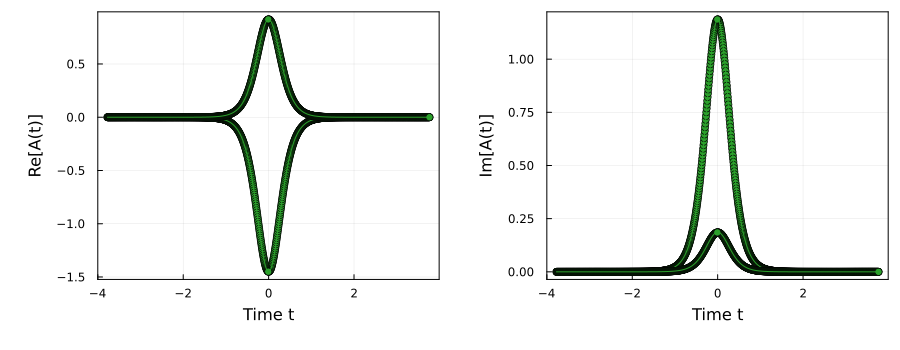

In [67]:
re_sml_plt = plot(frame=:box); im_sml_plt = plot(frame=:box)

# sml_vec[i_sml].out_amp or test_amp[:,i_sml,:]
i_sml = 25
color = palette(:tab20)[mod1(i_sml,20)]
plotCompare(sml_vec[i_sml].arr_time, test_amp[:,i_sml,:], anl_sml_amp[:,i_sml,:], re_sml_plt; 
    color = color, comp = real, margins = 2Plots.mm, legend=nothing, ylabel = "Re[A(t)]")
plotCompare(sml_vec[i_sml].arr_time, test_amp[:,i_sml,:], anl_sml_amp[:,i_sml,:], im_sml_plt; 
    legend=nothing, color = color, margins = 2Plots.mm,
    comp = imag, ylabel = "Im[A(t)]")

plot(re_sml_plt, im_sml_plt, size=(900,350))